# XMDF mesh results with pyramids-mesh

**XMDF** (eXtensible Model Data Format) is an HDF5 results container used by SMS/SRH-2D and other hydraulic tools. Crucially, an XMDF file stores *values only* - it has no mesh geometry of its own. pyramids-mesh therefore reads it in two steps: open the companion mesh (here a `.2dm` file), then **attach** the XMDF results to it.

This notebook reads `minimal.xmdf` together with its `minimal.2dm` mesh and showcases the `pyramids.netcdf.ugrid.UgridDataset` API end to end.

## Setup

Force a non-interactive matplotlib backend and define a `show()` helper that embeds each figure as a PNG - under the Agg backend nothing renders unless we save it ourselves.

In [1]:
import os
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display

def show():
    """Embed the current matplotlib figure as a PNG (Agg draws nothing on its own)."""
    from io import BytesIO
    buf = BytesIO()
    plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all"); buf.seek(0)
    display(Image(data=buf.read()))

In [2]:
from pathlib import Path
import numpy as np
from pyramids.netcdf.ugrid import UgridDataset

# Paths are relative to THIS notebook (docs/examples/), never the repo root.
# read_file takes a pathlib.Path - pass Path objects, never str().
DATA = Path("../../examples/data")
DATA.resolve()

WindowsPath('C:/python-environments/worktrees/pyramids-mesh/example-notebooks/examples/data')

## What is on disk

Two files: the mesh (`minimal.2dm`) and the results (`minimal.xmdf`).

In [3]:
for p in sorted((DATA / "xmdf").iterdir()):
    print(p.name, f"({p.stat().st_size:,} bytes)")

minimal.2dm (3,208 bytes)
minimal.xmdf (38,215 bytes)


## Quickstart: read the mesh, then attach the results

Reading the `.2dm` gives a `UgridDataset` carrying the mesh plus its static fields (`material`, `node_z`). `attach_data(<xmdf>)` returns a new dataset with the XMDF result variables added on top of that same geometry.

In [4]:
mesh = UgridDataset.read_file(DATA / "xmdf" / "minimal.2dm")
print("mesh variables:", mesh.data_variable_names)
ds = mesh.attach_data(DATA / "xmdf" / "minimal.xmdf")
print("after attach:  ", ds.data_variable_names)
ds

mesh variables: ['material', 'node_z']
after attach:   ['material', 'node_z', 'Minimum dt', 'Minimum dt_active']


UgridDataset(mesh='mesh2d', n_node=25, n_face=16, n_edge=0, variables=['material', 'node_z', 'Minimum dt', 'Minimum dt_active'])

The attach step added the XMDF results (`Minimum dt`, `Minimum dt_active`) to the mesh's own `material` and `node_z` fields - one dataset now holds geometry and results together.

## Explore the dataset

A `UgridDataset` wraps a UGRID-style unstructured mesh plus any data variables that ride on it. The scalar properties below describe the grid at a glance: how many nodes and faces it has, its coordinate reference system, and its spatial extent.

Note the small size (25 nodes, 16 quad faces): this is a deliberately minimal test mesh.

In [5]:
print("n_node:", ds.n_node)
print("n_face:", ds.n_face)
print("crs:   ", ds.crs)
print("epsg:  ", ds.epsg)
print("bounds:", ds.bounds)  # (xmin, ymin, xmax, ymax)

n_node: 25
n_face: 16
crs:    None
epsg:   None
bounds: (0.0, 0.0, 4.0, 4.0)


`crs`/`epsg` are often `None`: many hydraulic-model result files store coordinates without an embedded CRS, so pyramids reports the geometry faithfully and leaves georeferencing to you. The `bounds` tuple is the mesh envelope in the file's own coordinate units.

### Data variables

`data_variable_names` lists every field attached to the mesh. These are the real model results - water levels, depths, velocities - that make a results file worth reading.

In [6]:
ds.data_variable_names

['material', 'node_z', 'Minimum dt', 'Minimum dt_active']

`summary()` returns a tidy `pandas.DataFrame` of per-variable statistics (count, min, max, mean, std) - a quick sanity check on magnitudes and fill values.

In [7]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
material,16,1.0,1.000000,1.000000,0.000000
node_z,25,0.0,0.000000,0.000000,0.000000
Minimum dt,75,0.0,0.319275,0.191565,0.156412
Minimum dt_active,48,1.0,1.000000,1.000000,0.000000


## The Mesh2d geometry

`ds.mesh` is a `Mesh2d`: the topology the data variables are defined on. Nodes carry the `(x, y)` coordinates; `face_node_connectivity` says which nodes form each face (a row per face, padded to the maximum vertex count).

In [8]:
mesh = ds.mesh
nx, ny = np.asarray(mesh.node_x), np.asarray(mesh.node_y)
fnc = np.asarray(mesh.face_node_connectivity.data)
print("node_x:", nx.shape, " node_y:", ny.shape)
print("face_node_connectivity:", fnc.shape, " (n_face, max_vertices)")
fnc[:3]

node_x: (25,)  node_y: (25,)
face_node_connectivity: (16, 4)  (n_face, max_vertices)


array([[0, 3, 2, 1],
       [4, 0, 1, 5],
       [6, 4, 5, 7]])

`face_areas` gives the area of every face; `face_centroids` is a `(2, n_face)` array of face centre coordinates. Both are derived straight from the topology.

In [9]:
areas = np.asarray(mesh.face_areas)
cen = np.asarray(mesh.face_centroids)  # shape (2, n_face)
print("face_areas:", areas.shape, " mean area:", round(float(areas.mean()), 4))
print("face_centroids:", cen.shape)

face_areas: (16,)  mean area: 1.0
face_centroids: (2, 16)


## Wireframe - the bare mesh

`plot_outline()` draws the mesh edges with no data colouring. It is the fastest way to see the grid's shape, resolution, and how faces are distributed before looking at any results.

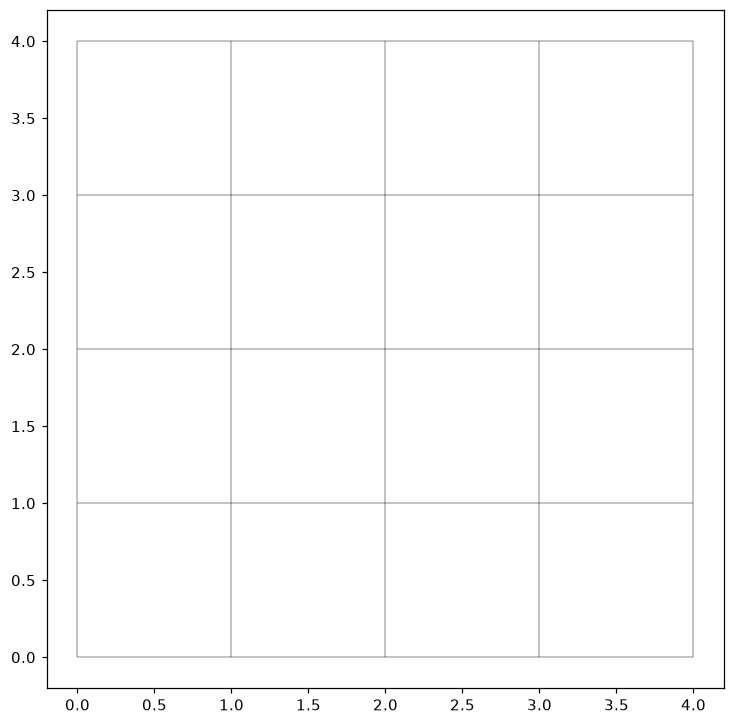

In [10]:
ds.plot_outline()
show()

## Mapping the real results

`node_z` is the bed elevation defined on the mesh, and `Minimum dt` is a solver diagnostic attached from the XMDF file (it carries a time axis, so we select the first step with `isel`). Both are genuine per-cell fields.

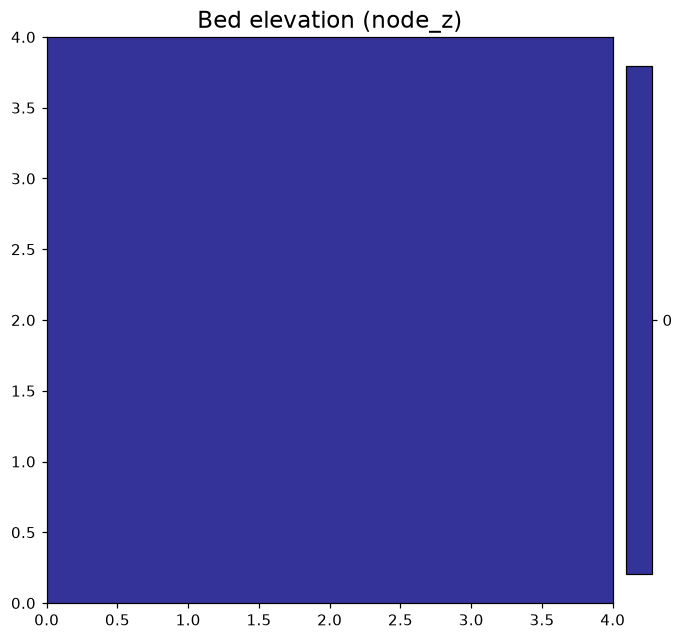

In [11]:
ds.plot("node_z", cmap="terrain", colorbar=True, title="Bed elevation (node_z)")
show()

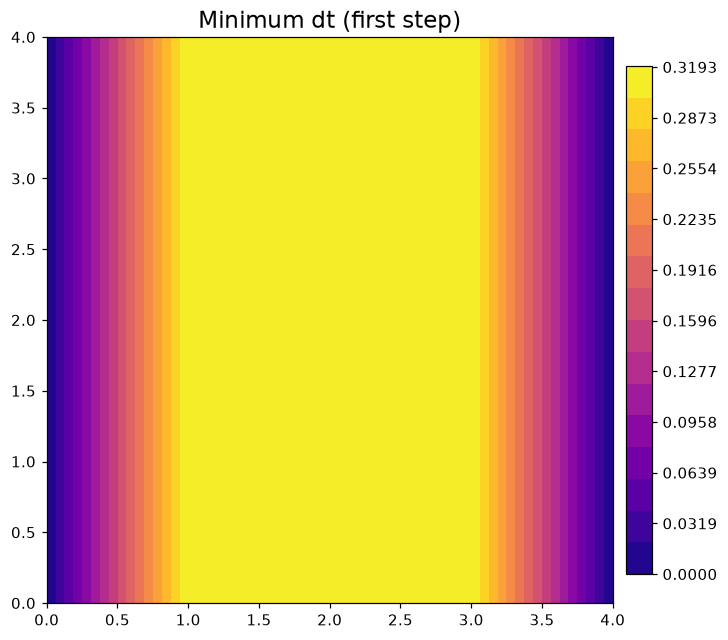

In [12]:
step = ds.isel(time=0)
step.plot("Minimum dt", cmap="plasma", colorbar=True, title="Minimum dt (first step)")
show()

## From mesh to GIS

A `UgridDataset` is not a dead end - it converts into the vector and raster types the rest of a GIS workflow expects. Everything below is reached through pyramids; this package only supplies the file-format driver that built the mesh.

### Faces as vector polygons

`to_geodataframe(variable_name=...)` turns every face into a polygon row carrying that variable's value - a standard GeoPandas `GeoDataFrame` you can join, filter, or export.

In [13]:
gdf = ds.to_geodataframe(variable_name="material")
print("rows:", len(gdf), " columns:", list(gdf.columns), " crs:", gdf.crs)
gdf.head()

rows: 16  columns: ['material', 'geometry']  crs: None


,material,geometry
0,1.0,"POLYGON ((1 1, 0 1, 0 0, 1 0, 1 1))"
1,1.0,"POLYGON ((2 1, 1 1, 1 0, 2 0, 2 1))"
2,1.0,"POLYGON ((3 1, 2 1, 2 0, 3 0, 3 1))"
3,1.0,"POLYGON ((4 1, 3 1, 3 0, 4 0, 4 1))"
4,1.0,"POLYGON ((1 2, 0 2, 0 1, 1 1, 1 2))"


Plotting that `GeoDataFrame` straight through GeoPandas (matplotlib under the hood) gives a choropleth of the same values, now as independent vector features.

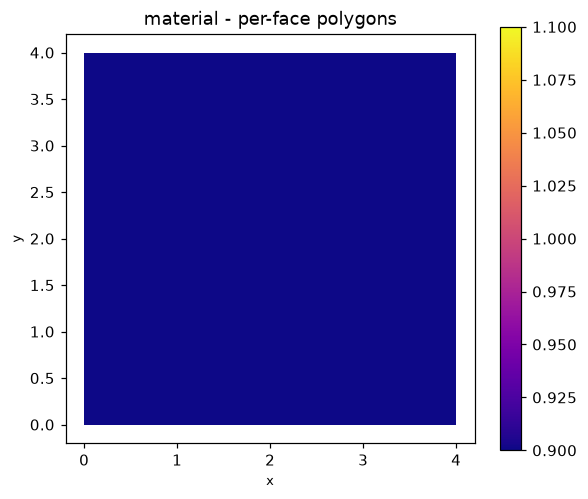

In [14]:
gdf.plot(column="material", cmap="plasma", legend=True, figsize=(6, 5))
plt.title("material - per-face polygons")
show()

### Dissolving into zones

`polygonize(variable)` merges neighbouring faces that share a value into larger polygons - handy for turning a noisy per-cell field into clean zones. It needs a single value per face, which is exactly what our working dataset holds.

dissolved polygons: 1  columns: ['value', 'geometry']


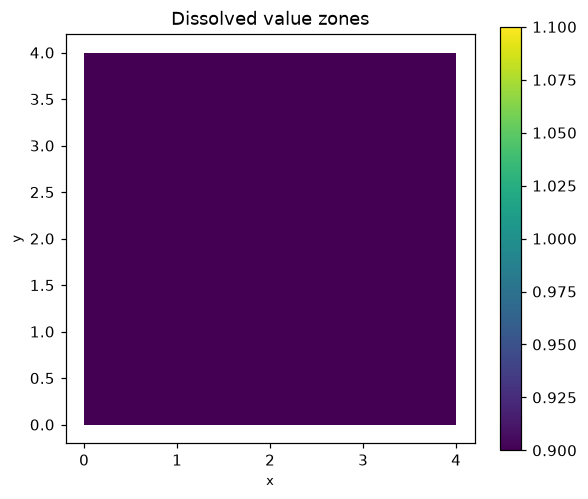

In [15]:
zones = ds.polygonize("material")
print("dissolved polygons:", len(zones), " columns:", list(zones.columns))
zones.plot(column="value", cmap="viridis", legend=True, figsize=(6, 5))
plt.title("Dissolved value zones")
show()

### Sampling at points

`sample(variable, x, y)` reads the value of the face that contains each query point. Here we probe the first few face centroids, so each query lands squarely inside a face.

In [16]:
cen = np.asarray(ds.mesh.face_centroids)
xs, ys = cen[0][:5], cen[1][:5]
vals = ds.sample("material", xs, ys)
for x, y, v in zip(xs, ys, np.asarray(vals)):
    print(f"({x:10.2f}, {y:10.2f}) -> {float(v):.4f}")

(      0.50,       0.50) -> 1.0000
(      1.50,       0.50) -> 1.0000
(      2.50,       0.50) -> 1.0000
(      3.50,       0.50) -> 1.0000
(      0.50,       1.50) -> 1.0000


### The mesh outline as one polygon

`bounding_polygon()` returns a single shapely polygon tracing the mesh's outer boundary - the model's wetted footprint, useful as a clip mask or extent reference.

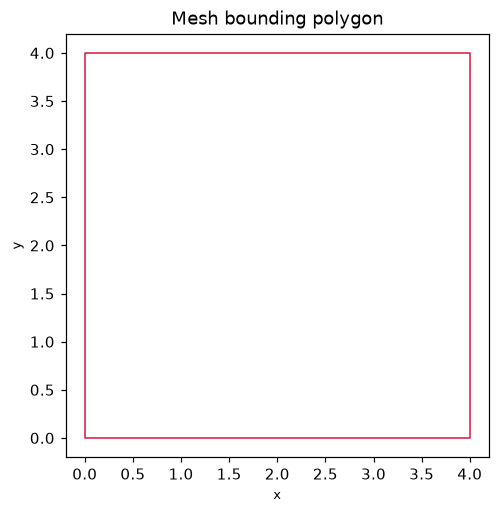

In [17]:
poly = ds.bounding_polygon()
import geopandas as gpd
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="crimson", figsize=(5, 5))
plt.title("Mesh bounding polygon")
show()

### Cropping to a sub-region

`subset_by_bounds(xmin, ymin, xmax, ymax)` returns a new, smaller `UgridDataset` holding only the faces inside the box - the same object type, so every operation above still applies. We derive a box from the mesh envelope so it works on any extent.

faces in full mesh: 16  -> in subset: 4


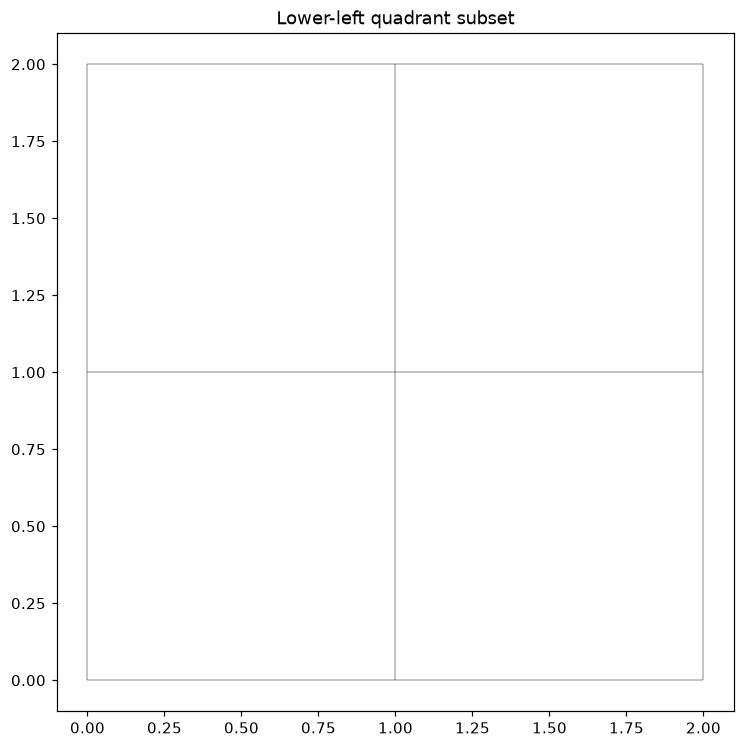

In [18]:
xmin, ymin, xmax, ymax = ds.bounds
mx, my = (xmin + xmax) / 2, (ymin + ymax) / 2
sub = ds.subset_by_bounds(xmin, ymin, mx, my)
print("faces in full mesh:", ds.n_face, " -> in subset:", sub.n_face)
sub.plot_outline()
plt.title("Lower-left quadrant subset")
show()

### Connectivity as a sparse graph

`sparse_adjacency()` exposes face-to-face adjacency as a SciPy sparse matrix, and `connected_components()` labels each face by which connected piece of the mesh it belongs to - the entry points for graph algorithms over the grid.

In [19]:
adj = ds.sparse_adjacency()
print("adjacency:", adj.shape, " non-zeros:", adj.nnz)
labels = ds.connected_components()
print("connected components:", len(np.unique(np.asarray(labels))))

adjacency: (16, 16)  non-zeros: 48
connected components: 1


### Circumcenters - not applicable here

`circumcenters()` is only defined for purely triangular meshes. This grid contains quad (or mixed-polygon) faces, so the call would raise `ValueError`. We note it and skip rather than force it.

### Self-contained rasterisation

`to_dataset(variable, cell_size=...)` samples the mesh onto a regular raster grid and returns a pyramids `Dataset`. Unlike `rasterize_like` / `regrid` - which need an existing reference grid and are therefore skipped here - this is self-contained: you only choose a cell size.

rasterised to: Dataset


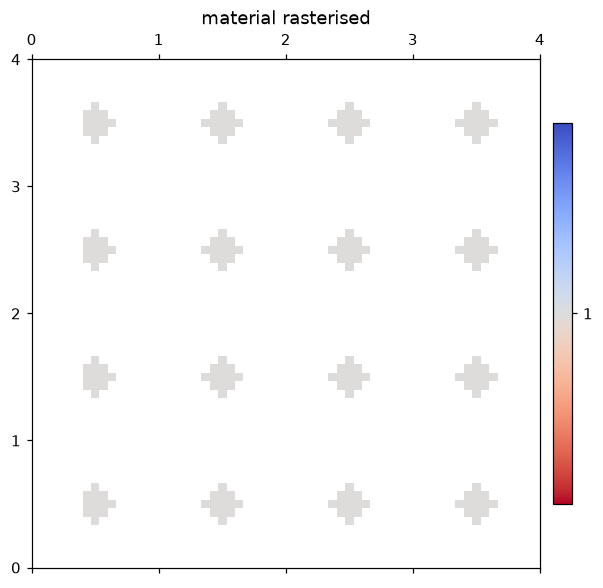

In [20]:
step_xy = (ds.bounds[2] - ds.bounds[0]) / 60
rast = ds.to_dataset("material", cell_size=step_xy)
print("rasterised to:", type(rast).__name__)
rast.plot()
plt.title("material rasterised")
show()

### Reprojection - skipped

`to_crs(...)` needs a *source* CRS to project from. This XMDF/2DM pair stores no CRS, so `ds.crs` is `None`. With no source CRS, reprojection is undefined, so we skip it; assign a CRS first if your coordinates are georeferenced.

### Back to xarray

`to_xarray()` hands the whole dataset back as an `xarray.Dataset`, so you can drop into the full xarray ecosystem (time selection, resampling, NetCDF export) whenever you need it.

In [21]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.data_vars)[:6]

('Dataset',
 ['mesh2d',
  'mesh2d_node_x',
  'mesh2d_node_y',
  'mesh2d_face_nodes',
  'material',
  'node_z'])

## Takeaway

XMDF is a *results-only* format: pyramids-mesh reads the mesh first (the `.2dm`), then `attach_data` layers the XMDF values onto it, producing one `UgridDataset`. From there the mesh behaves like any other pyramids object - plot its fields, convert faces to a `GeoDataFrame`, dissolve zones, crop, or rasterise. The driver's only job is parsing the file; every mesh and GIS operation lives upstream in pyramids.